<span></span>
<center>
<h1><b>Fall 2026<br/>
CSC-372 Project Part 7<br/></b></h1>

# Overfitting, Regularization and Generalization

</center>


<a href="https://colab.research.google.com/github/fahadsultan/csc372/blob/main/Project7.ipynb" target="_blank" align="right">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

<img src="Project7_2.png" width="100%">


In this part of the project, you will focus on understanding and mitigating overfitting in deep learning models. Your goal is to **demonstrate a significant improvement over a baseline and explain which methods contributed to it**. 

Apply each technique separately to a fresh model, keeping other settings fixed unless a change is required. Reuse the same training, validation, and test subsets throughout.

Use validation results to choose settings and stopping points. After those choices are finalized, evaluate the selected model on clean training and test images in evaluation mode.

For every technique, report:

* Training loss, test loss, and loss gap = test loss − training loss.

* Training accuracy, test accuracy, and accuracy gap = training accuracy − test accuracy.

Use ordinary cross-entropy on fine-class labels for evaluation, without label smoothing, regularization penalties, or auxiliary-task losses.

Compare both gaps with the baseline. Explain whether a smaller gap comes from improved test performance, reduced training performance, or both.

---

CIFAR-100 contains 60,000 color images, each 32 × 32 pixels, organized into 100 fine-grained classes  and 20 broader categories.

$$\begin{aligned}
\mathbf{x}_i \in & \mathbb{R}^{32 \times 32 \times 3} \\
\mathbf{X} \in & \mathbb{R}^{60,000 \times 3072} \\
\mathbf{y}_{fine} \in & \{1, \dots, 100\} \\
\mathbf{y}_{coarse} \in & \{1, \dots, 20\} \\
\end{aligned}$$

<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQNpW8BytiwnMnxFEcXaiAjb1oHsOhkrA3qNTBYDwTcMseKTG9LOONGeyqg&s=10" width="100%">

The dataset comes with predefined training and test splits of 50,000 and 10,000 images, respectively.

<mark>You are expected to randomly split the official training set into training and validation subsets of 40,000 and 10,000 images, respectively.

This train-validation split must be stratified, ensuring that each class is proportionally represented in both the training and validation subsets.</mark>

Your primary task is **100-class image classification**. For multi-task learning, also predict each image’s **20-class coarse category**.

Dataset and category information: [CIFAR-100](https://www.cs.toronto.edu/~kriz/cifar.html).



In [9]:
!pip install datasets

     |████████████████████████████████| 515 kB 2.0 MB/s eta 0:00:01
     |████████████████████████████████| 625 kB 34.8 MB/s eta 0:00:01
     |████████████████████████████████| 200 kB 31.8 MB/s eta 0:00:01
     |████████████████████████████████| 119 kB 29.6 MB/s eta 0:00:01
     |████████████████████████████████| 133 kB 37.4 MB/s eta 0:00:01
     |████████████████████████████████| 32.7 MB 1.0 MB/s eta 0:00:011
     |████████████████████████████████| 3.8 MB 67.2 MB/s eta 0:00:01
  Attempting uninstall: charset-normalizer
    Found existing installation: charset-normalizer 3.3.2
    Uninstalling charset-normalizer-3.3.2:
      Successfully uninstalled charset-normalizer-3.3.2
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2022.2.0
    Uninstalling fsspec-2022.2.0:
      Successfully uninstalled fsspec-2022.2.0
  Attempting uninstall: filelock
    Found existing installation: filelock 3.6.0
    Uninstalling filelock-3.6.0:
      Successfully uninstalled filelock-3.

In [26]:
%pip install --upgrade Pillow

     |████████████████████████████████| 5.3 MB 813 kB/s eta 0:00:01
  Attempting uninstall: Pillow
    Found existing installation: Pillow 9.0.1
    Uninstalling Pillow-9.0.1:
      Successfully uninstalled Pillow-9.0.1
Note: you may need to restart the kernel to use updated packages.


In [1]:
from datasets import load_dataset
ds = load_dataset("uoft-cs/cifar100")   # train / test splits

# fields: img, fine_label, coarse_label

In [2]:
ds

DatasetDict({
    train: Dataset({
        features: ['img', 'fine_label', 'coarse_label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'fine_label', 'coarse_label'],
        num_rows: 10000
    })
})

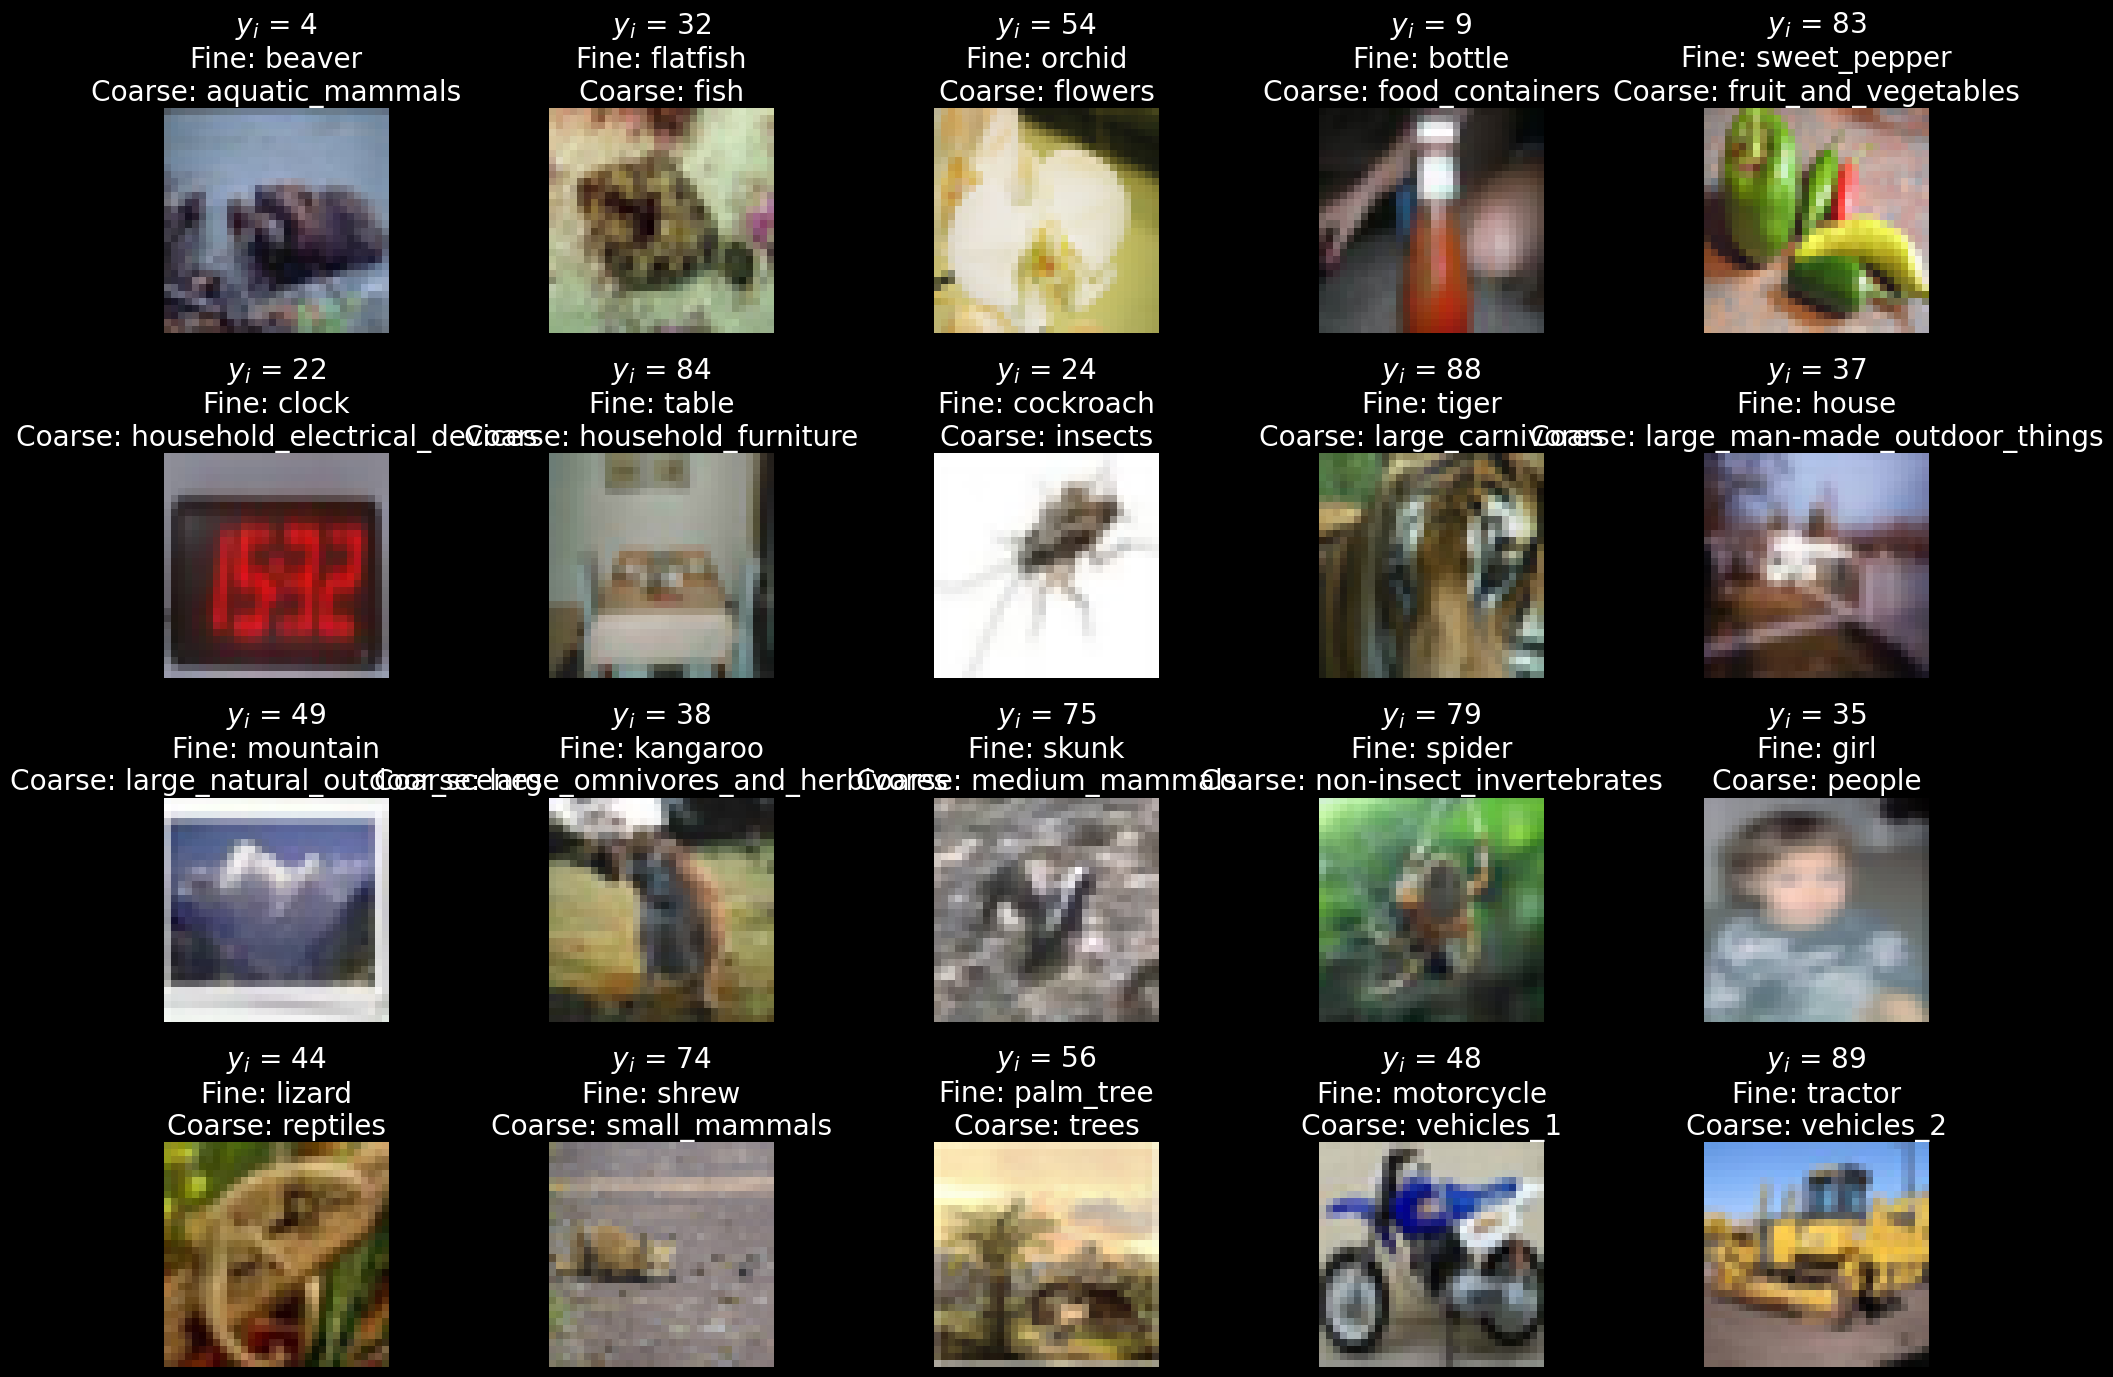

Train: 40000, Validation: 10000, Test: 10000


In [108]:
import numpy as np
from matplotlib import pyplot as plt

# Split complete rows so images and both labels stay aligned.
# Run this from the original ds, replacing your existing split code.
split = ds["train"].train_test_split(
    test_size=10_000,
    seed=42,
    stratify_by_column="fine_label"
)

train_ds = split["train"]
valid_ds = split["test"]
test_ds = ds["test"]

fine_names = train_ds.features["fine_label"]
coarse_names = train_ds.features["coarse_label"]

# Retrieve labels without loading every image.
y_train = np.array(train_ds["fine_label"])
coarse_train = np.array(train_ds["coarse_label"])

plt.style.use("dark_background")
fig, axes = plt.subplots(4, 5, figsize=(20, 14))

for label in range(20):
    i = np.flatnonzero(coarse_train == label)[0]
    example = train_ds[int(i)]
    ax = axes.flat[label]

    ax.imshow(example["img"])
    ax.set_title(
        f"$y_i$ = {example['fine_label']}\n"
        f"Fine: {fine_names.int2str(example['fine_label'])}\n"
        f"Coarse: {coarse_names.int2str(example['coarse_label'])}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

print(
    f"Train: {len(train_ds)}, "
    f"Validation: {len(valid_ds)}, "
    f"Test: {len(test_ds)}"
)

## 0. Baseline

Build a sequential feed-forward neural network model and train it from random initialization using cross-entropy loss.

For the baseline:

- Normalize the input images.
- Use no data augmentation, dropout, label smoothing, injected noise, or weight decay.
- Train for a fixed number of epochs.
- Save training and validation loss and accuracy after every epoch.
- Keep model size and training budget practical for repeated experiments.

Choose the optimizer, learning-rate schedule, batch size, and epoch budget before the main experiments. Keep them fixed unless a method requires a documented change.

<font color="orange">Note that `transforms.Compose` combines image transformations into a sequence and applies them in the order listed whenever an image is loaded. In this notebook, it converts images into PyTorch tensors using ToTensor() and normalizes each color channel using `Normalize()`. For data augmentation, we add transformations such as random crops and horizontal flips before `ToTensor()`. These random transformations can produce a different version of an image each time it is loaded during training. For validation and testing, we use only conversion and normalization so that evaluation images are not randomly altered.</font>



Report parameter count, training time, training accuracy, validation accuracy, and the generalization gap:

In [ ]:
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

images = ds["train"]["img"]
labels = ds["train"]["fine_label"]

# Reuse the existing stratified split.
X_train = train_ds["img"]
y_train = train_ds["fine_label"]

X_valid = valid_ds["img"]
y_valid = valid_ds["fine_label"]

X_test = test_ds["img"]
y_test = test_ds["fine_label"]


class MyDataset(Dataset):
    def __init__(self, X, y):
        self.features = X
        self.labels = y
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(
                (0.5071, 0.4867, 0.4408),
                (0.2675, 0.2565, 0.2761)
            ),
        ])

    def __getitem__(self, index):
        image = self.features[index]

        # Handles PIL images or original uint8 image arrays.
        if not isinstance(image, Image.Image):
            image = Image.fromarray(np.asarray(image))

        image = self.transform(image.convert("RGB"))
        label = torch.tensor(int(self.labels[index]), dtype=torch.long)
        return image, label

    def __len__(self):
        return len(self.features)


train_dataset = MyDataset(X_train, y_train)
val_dataset = MyDataset(X_valid, y_valid)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=64, shuffle=False
)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")



In [74]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(32 * 32 * 3, 512),
    nn.ReLU(),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 100),
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

num_epochs = 25

train_loss_history = []
val_loss_history = []

train_accuracy_history = []
val_accuracy_history = []

for epoch in range(num_epochs):
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        batch_size = targets.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (outputs.argmax(dim=1) == targets).sum().item()
        train_count += batch_size

    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_count = 0

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            batch_size = targets.size(0)
            val_loss_sum += loss.item() * batch_size
            val_correct += (outputs.argmax(dim=1) == targets).sum().item()
            val_count += batch_size

    train_loss_history.append(train_loss_sum / train_count)
    val_loss_history.append(val_loss_sum / val_count)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train loss: {train_loss_sum / train_count:.4f} | "
        f"Train accuracy: {train_correct / train_count:.2%} | "
        f"Val loss: {val_loss_sum / val_count:.4f} | "
        f"Val accuracy: {val_correct / val_count:.2%}"
    )

    train_accuracy_history.append(train_correct / train_count)
    val_accuracy_history.append(val_correct / val_count)

Epoch 1/25 | Train loss: 3.8296 | Train accuracy: 12.50% | Val loss: 3.6093 | Val accuracy: 16.26%
Epoch 2/25 | Train loss: 3.4446 | Train accuracy: 18.59% | Val loss: 3.4817 | Val accuracy: 18.95%
Epoch 3/25 | Train loss: 3.2802 | Train accuracy: 21.14% | Val loss: 3.4546 | Val accuracy: 19.09%
Epoch 4/25 | Train loss: 3.1357 | Train accuracy: 23.42% | Val loss: 3.4379 | Val accuracy: 19.79%
Epoch 5/25 | Train loss: 3.0219 | Train accuracy: 25.55% | Val loss: 3.4726 | Val accuracy: 19.80%
Epoch 6/25 | Train loss: 2.9071 | Train accuracy: 27.66% | Val loss: 3.4515 | Val accuracy: 20.02%
Epoch 7/25 | Train loss: 2.7843 | Train accuracy: 29.74% | Val loss: 3.5266 | Val accuracy: 20.32%
Epoch 8/25 | Train loss: 2.6722 | Train accuracy: 32.13% | Val loss: 3.6012 | Val accuracy: 20.64%
Epoch 9/25 | Train loss: 2.5626 | Train accuracy: 34.35% | Val loss: 3.6137 | Val accuracy: 21.87%
Epoch 10/25 | Train loss: 2.4460 | Train accuracy: 36.81% | Val loss: 3.7931 | Val accuracy: 20.92%
Epoch 11/

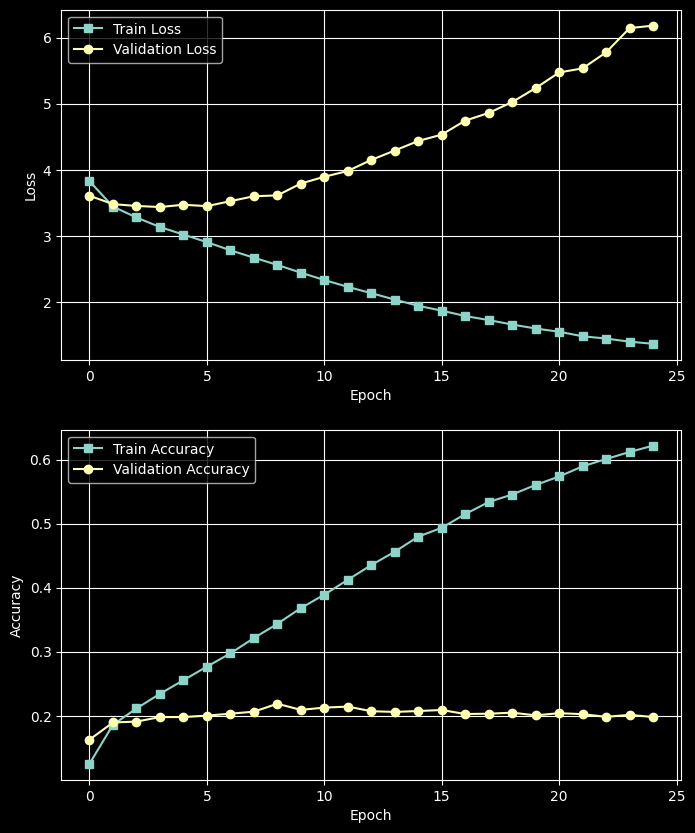

In [106]:
fig, axs = plt.subplots(2, 1, figsize=(8, 10))

axs[0].plot(train_loss_history, label="Train Loss", marker='s')
axs[0].plot(val_loss_history, label="Validation Loss", marker='o')
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend()
axs[0].grid(True)

axs[1].plot(train_accuracy_history, label="Train Accuracy", marker='s')
axs[1].plot(val_accuracy_history, label="Validation Accuracy", marker='o')
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Accuracy")
axs[1].legend()
axs[1].grid(True)

plt.show()



**Generalization gap = training accuracy − validation accuracy.**

If the model does not overfit, explain what you observe. Do not deliberately weaken the baseline to make later improvements look larger.


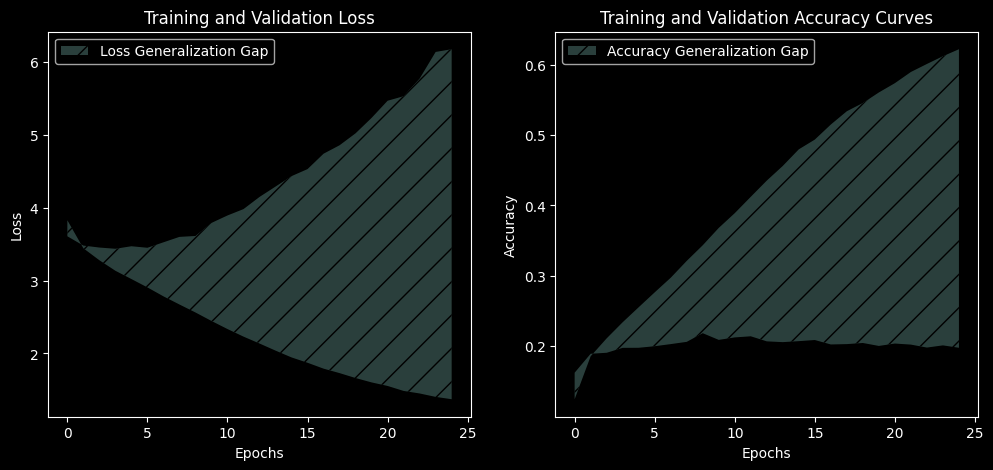

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].fill_between(range(len(train_loss_history)), val_loss_history, train_loss_history, alpha=0.3, label='Loss Generalization Gap', hatch='/')
axs[0].legend()
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].set_title('Training and Validation Loss')

axs[1].fill_between(range(len(train_accuracy_history)), train_accuracy_history, val_accuracy_history, alpha=0.3, label='Accuracy Generalization Gap', hatch='/')
axs[1].legend()
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].set_title('Training and Validation Accuracy Curves')

plt.show()

In [103]:
X_test

Column([<PIL.PngImagePlugin.PngImageFile image mode=RGB size=32x32 at 0x7F824052B520>, <PIL.PngImagePlugin.PngImageFile image mode=RGB size=32x32 at 0x7F824052BE80>, <PIL.PngImagePlugin.PngImageFile image mode=RGB size=32x32 at 0x7F824052B0A0>, <PIL.PngImagePlugin.PngImageFile image mode=RGB size=32x32 at 0x7F824052BC40>, <PIL.PngImagePlugin.PngImageFile image mode=RGB size=32x32 at 0x7F824052B790>, ...])

In [112]:
from sklearn.metrics import classification_report
from torch.utils.data import DataLoader
import torch

test_dataset = MyDataset(X_test, y_test)
test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False
)

model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for inputs, targets in test_loader:
        outputs = model(inputs.to(device))
        predictions = outputs.argmax(dim=1)

        y_true.extend(targets.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

class_names = ds["train"].features["fine_label"].names

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(100)),
    target_names=class_names,
    digits=3,
    zero_division=0,
))

               precision    recall  f1-score   support

        apple      0.433     0.550     0.485       100
aquarium_fish      0.336     0.380     0.357       100
         baby      0.119     0.190     0.147       100
         bear      0.131     0.140     0.135       100
       beaver      0.220     0.090     0.128       100
          bed      0.220     0.280     0.247       100
          bee      0.142     0.190     0.162       100
       beetle      0.258     0.310     0.282       100
      bicycle      0.229     0.190     0.208       100
       bottle      0.315     0.390     0.348       100
         bowl      0.167     0.070     0.099       100
          boy      0.221     0.170     0.192       100
       bridge      0.209     0.270     0.236       100
          bus      0.383     0.180     0.245       100
    butterfly      0.198     0.170     0.183       100
        camel      0.171     0.130     0.148       100
          can      0.377     0.200     0.261       100
       ca

## 1. Weight-penalty regularization

Add an L2 penalty to the loss, then compare it with decoupled weight decay.

$$
L = L_{CE} + \lambda \sum_i w_i^2
$$

- Sweep λ ∈ {1e-5, 1e-4, 5e-4, 1e-3, 5e-3}, implemented as an explicit penalty with Adam.
- Repeat the best λ using `AdamW(weight_decay=...)` and compare. Explain why L2-in-the-loss and decoupled decay are not equivalent under Adam.
- Optional: L1 penalty; report the fraction of near-zero weights (|w| < 1e-3).

**Explicit regularization** 

Add L2 regularization or decoupled weight decay. Explain which you used. 

Does discouraging large weights reduce overfitting?

In [ ]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(32 * 32 * 3, 512),
    nn.ReLU(),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 100),
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

num_epochs = 25

train_with_reg_loss_history = []
val_with_reg_loss_history = []

train_with_reg_accuracy_history = []
val_with_reg_accuracy_history = []

# Implement training loop with L2 regularization (weight decay)

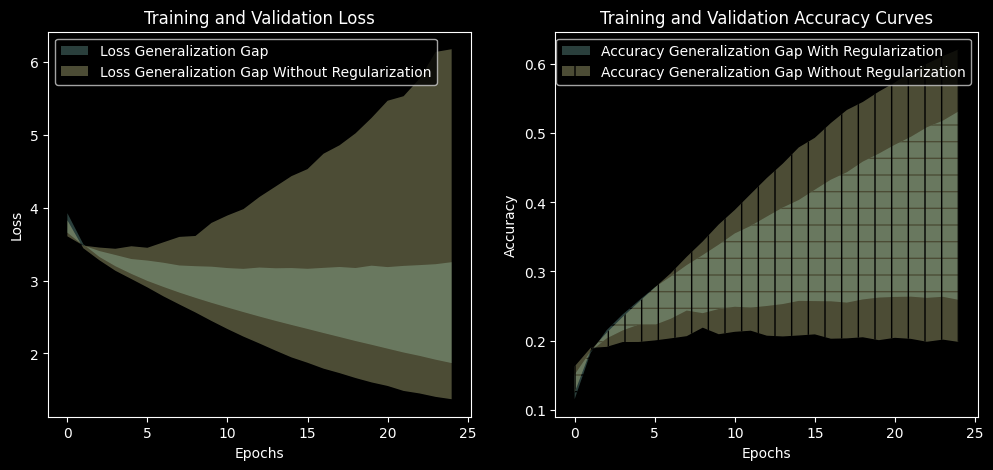

In [ ]:
# Plot with regularization and compare with without regularization

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].fill_between(range(len(train_with_reg_loss_history)), val_with_reg_loss_history, train_with_reg_loss_history, alpha=0.3, label='Loss Generalization Gap')
axs[0].fill_between(range(len(train_loss_history)), val_loss_history, train_loss_history, alpha=0.3, label='Loss Generalization Gap Without Regularization')
axs[0].legend()
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].set_title('Training and Validation Loss')

axs[1].fill_between(range(len(train_with_reg_accuracy_history)), train_with_reg_accuracy_history, val_with_reg_accuracy_history, alpha=0.3, label='Accuracy Generalization Gap With Regularization', hatch='-')
axs[1].fill_between(range(len(train_accuracy_history)), val_accuracy_history, train_accuracy_history, alpha=0.3, label='Accuracy Generalization Gap Without Regularization', hatch='|')
axs[1].legend()
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].set_title('Training and Validation Accuracy Curves')

plt.show()

## 2. Early stopping

Monitor validation loss each epoch and stop when it hasn't improved for `patience` epochs, restoring the best weights.

Consider `patience` $\in \{3, 5, 10, 20\}$.

Report the stopping epoch, the restored epoch, and the compute saved relative to 60 epochs.

Can you improve generalization while reducing training time? Does stopping on validation *loss* vs. validation *accuracy* pick different epochs? 


## 3. Noise on inputs

During training only, add zero-mean Gaussian noise with standard deviation σ to each normalized input batch: `x + σ·randn_like(x)`. Here, `randn_like(x)` generates a tensor of the same shape as `x` with elements drawn from a standard normal distribution (mean 0, variance 1).

Consider $\sigma \in \{0.01, 0.05, 0.1, 0.2, 0.4\}$

Connect your result to the known equivalence between small input noise and a Tikhonov (L2-type) penalty on the input gradient.

Does training on perturbed inputs improve robustness or clean accuracy?


## 4. Label smoothing

Train the baseline model using `nn.CrossEntropyLoss(label_smoothing=p)` Consider different values of `p` such as 0.05, 0.1, 0.2, and 0.3.

Compare its training–test loss and accuracy gaps with the baseline from 0. 

For evaluation, use ordinary cross-entropy without label smoothing.

Does label smoothing reduce the generalization gap?


## 5. Data augmentation

Train a model using random crops (RandomCrop(32, padding=4)) and horizontal flips (RandomHorizontalFlip()) on training images only.

Compare its training–test loss and accuracy gaps with the baseline. For evaluation, use clean, unaugmented images for both datasets.

Does data augmentation reduce the generalization gap?

In [ ]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5071, 0.4867, 0.4408),
        (0.2675, 0.2565, 0.2761),
    ),
])




## 6. Multi-task learning

Modify the baseline model to share its hidden layers between two output layers: one predicting 100 fine classes and another predicting 20 coarse categories.

Train using the sum of the two cross-entropy losses:

$$L = L_{\text{fine}} + L_{\text{coarse}}.$$

Compare its training–test loss and accuracy gaps with the baseline, using only fine-class predictions and fine-class cross-entropy for evaluation.

Does learning both tasks reduce the generalization gap?

## 7. Transfer learning

Use a ResNet-18 pretrained on ImageNet. Freeze its existing layers and replace its final classification layer with a new layer that predicts the 100 CIFAR-100 classes. Train only this new layer.

Compare its training–test loss and accuracy gaps with the baseline.

Because this experiment changes both the architecture and the initial weights, differences from the baseline cannot be attributed to pretraining alone.

Does the pretrained model reduce the generalization gap? Does it also change training and test performance?

### Step 1: Load the pretrained model

The pretrained model has already learned image features from ImageNet. We will reuse those features and train a new final classifier for CIFAR-100.


In [ ]:
import time
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.IMAGENET1K_V1
transfer_model = resnet18(weights=weights)

print(transfer_model.fc)

In [ ]:

model = transfer_model
model.eval()

image = ds["test"][0]["img"].convert("RGB")  # One CIFAR-100 image
x = weights.transforms()(image)             # Resize, crop, normalize
x = x.unsqueeze(0)                          # Add batch dimension

with torch.no_grad():
    scores = model(x)

predicted_class = scores.argmax(dim=1).item()

print("Input shape:", x.shape)       # [1, 3, 224, 224]
print("Output shape:", scores.shape) # [1, 1000]
print("Prediction:", weights.meta["categories"][predicted_class])

The original final layer predicts 1,000 ImageNet classes. We need 100 outputs instead.

### Step 2: Freeze the existing layers and replace the classifier**

requires_grad = False prevents the optimizer from updating the pretrained parameters. The new layer has trainable parameters by default.

In [ ]:
# Freeze all existing parameters.
for parameter in transfer_model.parameters():
    parameter.requires_grad = False

# Replace the original classifier with a trainable CIFAR-100 classifier.
num_features = transfer_model.fc.in_features
transfer_model.fc = nn.Linear(num_features, 100)

transfer_model = transfer_model.to(device)

print("New classifier:", transfer_model.fc)
print(
    "Trainable parameters:",
    sum(p.numel() for p in transfer_model.parameters()
        if p.requires_grad)
)

In [ ]:
The order matters: freeze the existing model before creating the new layer.

### Step 3: Prepare images for the pretrained model

Use the preprocessing supplied with the pretrained weights. It resizes and center-crops images to 224 × 224, converts them into tensors, and applies ImageNet normalization.
Use the same preprocessing for training, validation, and testing in this experiment.

In [ ]:
transfer_transform = weights.transforms()


class TransferDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        example = self.rows[int(index)]

        image = example["img"].convert("RGB")
        image = transfer_transform(image)

        label = int(example["fine_label"])
        return image, label


# Reuse the existing stratified split. Do not split the data again.
transfer_train_dataset = TransferDataset(train_ds)
transfer_valid_dataset = TransferDataset(valid_ds)
transfer_test_dataset = TransferDataset(test_ds)

transfer_train_loader = DataLoader(
    transfer_train_dataset, batch_size=64, shuffle=True
)

transfer_valid_loader = DataLoader(
    transfer_valid_dataset, batch_size=64, shuffle=False
)

transfer_test_loader = DataLoader(
    transfer_test_dataset, batch_size=64, shuffle=False
)

If memory is limited, reduce the batch size and document the change.

### Step 4: Define the loss, optimizer, and evaluation function

The model returns raw class scores, so use cross-entropy directly. Only the new classifier is passed to the optimizer.

In [ ]:
optimizer = torch.optim.Adam(
    transfer_model.fc.parameters(),
    lr=1e-3
)

criterion = nn.CrossEntropyLoss()


def evaluate_transfer(model, loader):
    model.eval()

    loss_sum = 0.0
    correct = 0
    count = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            count += labels.size(0)
            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()

    return loss_sum / count, correct / count

### Step 5: Train the new classifier

Keep the frozen model in evaluation mode while training the classifier. ResNet contains batch-normalization layers whose stored statistics would otherwise change during training.

`eval()` does not disable gradients: the new classifier can still learn

Input shape: torch.Size([1, 3, 224, 224])
Output shape: torch.Size([1, 1000])
Prediction: volcano


Note that the imported ResNet-18 model has a fully connected layer `model.fc` at the end, which we replace with a new `nn.Linear` layer to match the number of classes in our dataset:

In [115]:
model.fc.in_features

512

In [119]:
model.layer1[0].conv1.in_channels

64

## 8. Ensembling

Train two baseline neural networks that differ only in their random seeds. Form an ensemble by averaging their predicted class probabilities (softmax outputs), then select the class with the highest average probability. Do not average predicted class IDs.

Evaluate all models on the same held-out test set. 

Report the ensemble’s total training time, inference time, and model storage requirements relative to a single baseline model, using the same hardware and inference batch size.

Does the ensemble’s improvement in generalization justify its additional inference time and storage requirements?


## 9. Dropout

Add dropout (`torch.nn.Dropout`) before each fully connected layer.

Consider $p \in \{0.1, 0.25, 0.5, 0.7\}$ as the dropout probability for fully connected layers.

Note that you should call `model.eval()` at evaluation time, which disables dropout and ensures deterministic behavior. Dropout is only active during training when `model.train()` is set.

Add dropout at documented locations and tune its probability.

How does dropout placement or strength affect learning?

## 10. Noise on weights

Train the baseline model with temporary Gaussian noise added to its weights before each forward pass:

$$
\tilde{w} = w + 0.05\,|w|\,z,
\qquad z \sim \mathcal{N}(0,1).
$$

Sample fresh noise for each training batch. After `loss.backward()`, restore the original weights before calling `optimizer.step()`.

Evaluate using clean weights. Compare the training–test loss and accuracy gaps with the baseline.

Add noise using  `torch.randn_like(x)`. Randn_like generates a tensor of the same shape as `x` with elements drawn from a standard normal distribution i.e. with mean 0 and variance 1.

For example, for a weight tensor `w`, you can add noise as

```python
z = torch.randn_like(w)
w_noisy = w + 0.05 * w.abs() * z
```

Does weight noise reduce the generalization gap?